# 01 · Exploratory analysis
**Study Smarter, Not Harder** · Portuguese course file (n = 649) unless stated.

Plan from the readme: distributions, group means by study time, the G3 = 0 (zero-grade case) profile and the
Fisher test by school, who studies more (confounding), and the absences-vs-grade picture.
All figures are saved to `figures/`. Pilot numbers in the readme section 5 are checked inline.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

PROC = Path("../data/processed")
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#9a9a94"
sns.set_theme(style="whitegrid", context="talk", rc={"grid.color": "#e6e6e3", "axes.edgecolor": "#bdbdb8",
                                                      "figure.dpi": 100, "savefig.dpi": 200})
ST_LABELS = {1: "<2 h", 2: "2-5 h", 3: "5-10 h", 4: ">10 h"}

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    print("saved figures/" + name + ".png")

df = pd.read_csv(PROC / "student-por_clean.csv")
mat = pd.read_csv(PROC / "student-mat_clean.csv")
df["study"] = pd.Categorical(df.studytime.map(ST_LABELS), list(ST_LABELS.values()), ordered=True)
nz = df[~df.zero_grade]
print(df.shape, "| zero-grade cases:", int(df.zero_grade.sum()))

(649, 36) | zero-grade cases: 15


## 1. The outcome: distribution of G3

count    649.00
mean      11.91
std        3.23
min        0.00
25%       10.00
50%       12.00
75%       14.00
max       19.00
Name: G3, dtype: float64
G3 == 0: 15 | next-lowest grade: 1
saved figures/01_g3_distribution.png


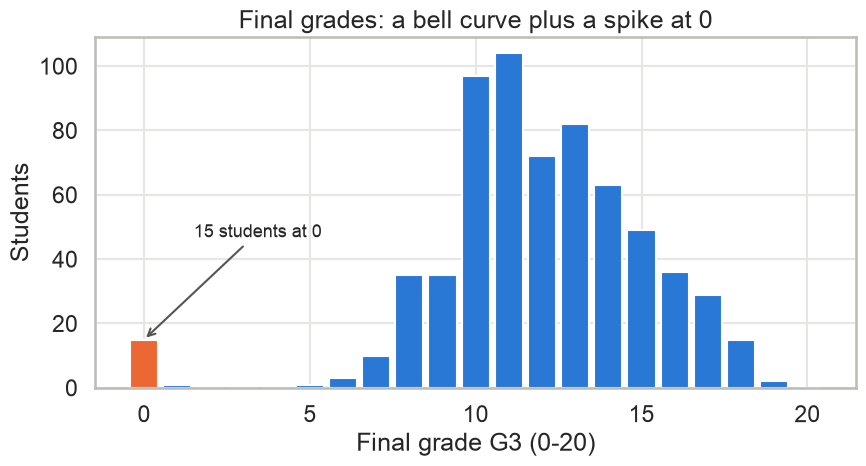

In [2]:
print(df.G3.describe().round(2))
print("G3 == 0:", int((df.G3 == 0).sum()), "| next-lowest grade:", df.loc[df.G3 > 0, "G3"].min())
fig, ax = plt.subplots(figsize=(9, 5))
counts = df.G3.value_counts().reindex(range(21), fill_value=0)
ax.bar(counts.index, counts.values, color=[ORANGE if g == 0 else BLUE for g in counts.index], width=0.85)
ax.set(xlabel="Final grade G3 (0-20)", ylabel="Students", title="Final grades: a bell curve plus a spike at 0")
ax.annotate(f"{counts[0]} students at 0", (0, counts[0]), xytext=(1.5, counts.max() * 0.45),
            arrowprops=dict(arrowstyle="->", color="#555"), fontsize=13)
savefig(fig, "01_g3_distribution")

**Interpretation:** Most final grades sit between 8 and 17 (mean 11.91, median 12), but 15 students score exactly 0 and the next-lowest grade is 1, so the zeros look like a separate group rather than the tail of the bell curve.

## 2. Study time: group sizes and means (clue 1)

        count   mean   std    se  ci_lo  ci_hi
study                                         
<2 h      212  10.84  3.22  0.22  10.41  11.28
2-5 h     305  12.09  3.24  0.19  11.73  12.46
5-10 h     97  13.23  2.50  0.25  12.72  13.73
>10 h      35  13.06  3.04  0.51  12.01  14.10
gap 5-10 h minus <2 h: 2.38


saved figures/02_g3_by_studytime.png


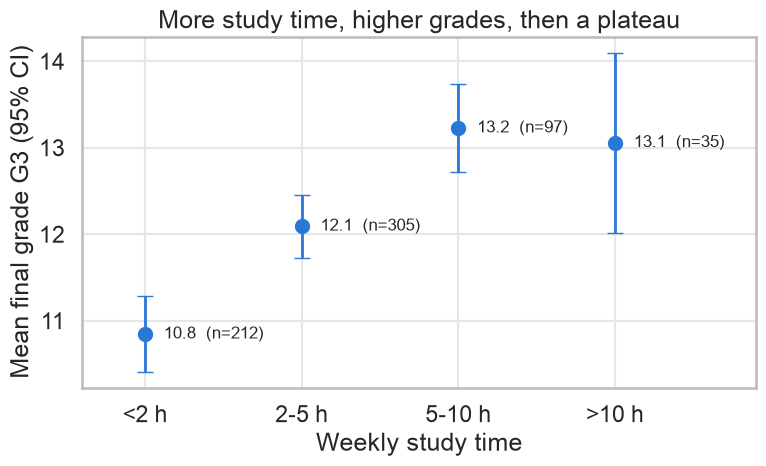

In [3]:
tab = df.groupby("study", observed=True).G3.agg(["count", "mean", "std"])
tab["se"] = tab["std"] / np.sqrt(tab["count"])
tab["ci_lo"] = tab["mean"] - stats.t.ppf(0.975, tab["count"] - 1) * tab["se"]
tab["ci_hi"] = tab["mean"] + stats.t.ppf(0.975, tab["count"] - 1) * tab["se"]
print(tab.round(2))
print("gap 5-10 h minus <2 h:", round(tab.loc["5-10 h", "mean"] - tab.loc["<2 h", "mean"], 2))
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(tab))
ax.errorbar(x, tab["mean"], yerr=[tab["mean"] - tab.ci_lo, tab.ci_hi - tab["mean"]], fmt="o", color=BLUE,
            ms=10, lw=2, capsize=6)
for i, (m, n) in enumerate(zip(tab["mean"], tab["count"])):
    ax.text(i + 0.12, m, f"{m:.1f}  (n={n})", va="center", fontsize=12)
ax.set_xticks(x, tab.index)
ax.set(xlabel="Weekly study time", ylabel="Mean final grade G3 (95% CI)", xlim=(-0.4, 3.9),
       title="More study time, higher grades, then a plateau")
savefig(fig, "02_g3_by_studytime")

**Interpretation:** Mean G3 rises from 10.84 (<2 h) to 12.09 and 13.23 (5-10 h), a 2.38-point gap, then flattens at 13.06 for >10 h, whose wide CI (12.0-14.1) reflects only 35 students.

## 3. Earlier grades: how strongly G1 and G2 predict G3

       G1     G2     G3
G1  1.000  0.865  0.826
G2  0.865  1.000  0.919
G3  0.826  0.919  1.000
saved figures/03_g1_g2_vs_g3.png


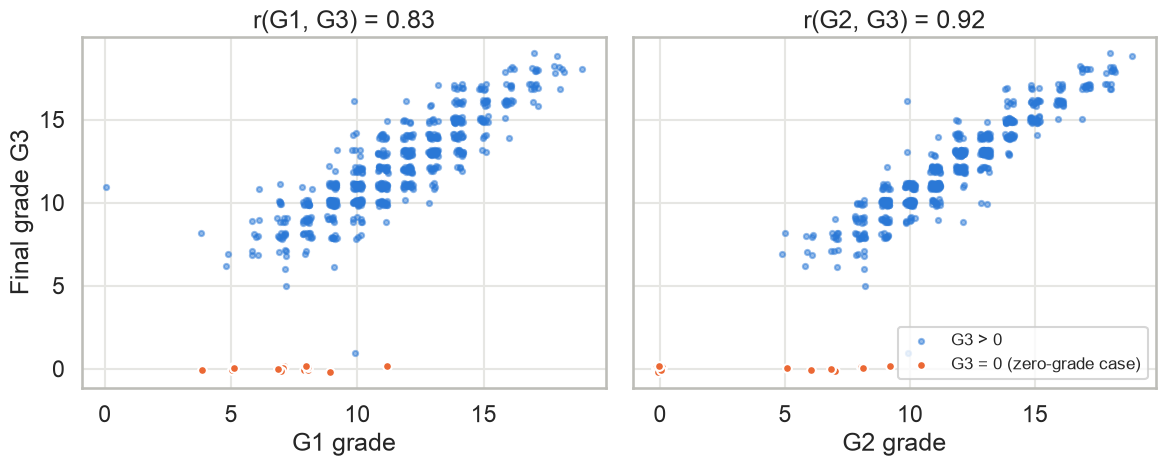

In [4]:
print(df[["G1", "G2", "G3"]].corr().round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, g in zip(axes, ["G1", "G2"]):
    jit = np.random.default_rng(0).uniform(-0.2, 0.2, (2, len(df)))
    ax.scatter(df[g][~df.zero_grade] + jit[0][~df.zero_grade], df.G3[~df.zero_grade] + jit[1][~df.zero_grade], s=14, alpha=0.5,
               color=BLUE, label="G3 > 0")
    ax.scatter(df[g][df.zero_grade] + jit[0][df.zero_grade], df.G3[df.zero_grade] + jit[1][df.zero_grade], s=40, color=ORANGE,
               edgecolor="white", lw=1.5, label="G3 = 0 (zero-grade case)")
    ax.set(xlabel=f"{g} grade", title=f"r({g}, G3) = {df[g].corr(df.G3):.2f}")
axes[0].set_ylabel("Final grade G3")
axes[1].legend(loc="lower right", fontsize=12)
savefig(fig, "03_g1_g2_vs_g3")

**Interpretation:** Earlier grades are strong predictors (r = 0.83 for G1 and 0.92 for G2 with G3), and the zero-grade cases sit far below the line, with G1 around 4-11 but G3 = 0.

## 4. The zero-grade cases: who has G3 = 0?

In [5]:
z = df[df.zero_grade]
print(f"zero-grade cases: {len(z)} of {len(df)}; with absences == 0: {(z.absences == 0).sum()} "
      f"(vs {(df.absences == 0).mean():.1%} of all students)")
print(f"zero-grade mean G1 = {z.G1.mean():.2f}, mean G2 = {z.G2.mean():.2f} (G3 > 0: {nz.G1.mean():.2f}, {nz.G2.mean():.2f})")
print("zero-grade cases by school:", z.school.value_counts().to_dict(), "| school sizes:", df.school.value_counts().to_dict())
ct = pd.crosstab(df.school, df.zero_grade)
print(ct)
odds, p = stats.fisher_exact(ct)
print(f"Fisher's exact (zero-grade x school): odds ratio = {odds:.1f}, p = {p:.2e}")
zm = mat[mat.zero_grade]
print(f"maths file: zero-grade cases = {len(zm)} of {len(mat)}, with absences == 0: {(zm.absences == 0).sum()}")
z[["school", "sex", "age", "studytime", "failures", "absences", "G1", "G2", "G3"]].sort_values("G2")

zero-grade cases: 15 of 649; with absences == 0: 15 (vs 37.6% of all students)
zero-grade mean G1 = 7.07, mean G2 = 3.80 (G3 > 0: 11.50, 11.75)
zero-grade cases by school: {'MS': 14, 'GP': 1} | school sizes: {'GP': 423, 'MS': 226}
zero_grade  False  True 
school                  
GP            422      1
MS            212     14
Fisher's exact (zero-grade x school): odds ratio = 27.9, p = 3.04e-06
maths file: zero-grade cases = 38 of 395, with absences == 0: 38


,school,sex,age,studytime,failures,absences,G1,G2,G3
440,MS,M,16,2,0,0,7,0,0
563,MS,M,17,1,1,0,7,0,0
567,MS,M,18,1,1,0,4,0,0
597,MS,F,18,2,1,0,9,0,0
603,MS,F,18,2,0,0,5,0,0
605,MS,F,19,1,1,0,5,0,0
610,MS,F,19,2,3,0,8,0,0
626,MS,F,18,2,0,0,7,5,0
583,MS,F,18,1,1,0,8,6,0
519,MS,M,16,2,0,0,8,7,0


In [6]:
prof = (df.assign(group=np.where(df.zero_grade, "G3 = 0", "G3 > 0"))
          .groupby("group")[["G1", "G2", "absences", "failures"]].mean().round(2))
prof["share_MS"] = df.groupby(np.where(df.zero_grade, "G3 = 0", "G3 > 0")).school.apply(lambda s: (s == "MS").mean()).round(2)
prof["share_abs0"] = df.groupby(np.where(df.zero_grade, "G3 = 0", "G3 > 0")).absences.apply(lambda s: (s == 0).mean()).round(2)
prof

,G1,G2,absences,failures,share_MS,share_abs0
group,,,,,,
G3 = 0,7.07,3.80,0.00,0.80,0.93,1.00
G3 > 0,11.50,11.75,3.75,0.21,0.33,0.36


**Interpretation:** All 15 zero-grade cases have 0 absences (vs 37.6% of all students), 14 of the 15 are at MS (Fisher's exact OR = 27.9, p = 3.0e-6), and their G2 averages 3.80 (7 of them already had G2 = 0) vs 11.75 for everyone else, which fits students leaving school, not perfect attendance. The maths file shows the same pattern: 38 of 38 zeros have 0 absences.

## 5. Absences vs final grade, zero-grade cases highlighted (twist 2)

absences: {'count': 649.0, 'mean': 3.66, 'std': 4.64, 'min': 0.0, '25%': 0.0, '50%': 2.0, '75%': 6.0, 'max': 32.0}
all     n=649: Pearson r(absences, G3) = -0.091, p = 0.02
G3 > 0  n=634: Pearson r(absences, G3) = -0.196, p = 6.5e-07


saved figures/04_absences_vs_g3_zero_grades.png


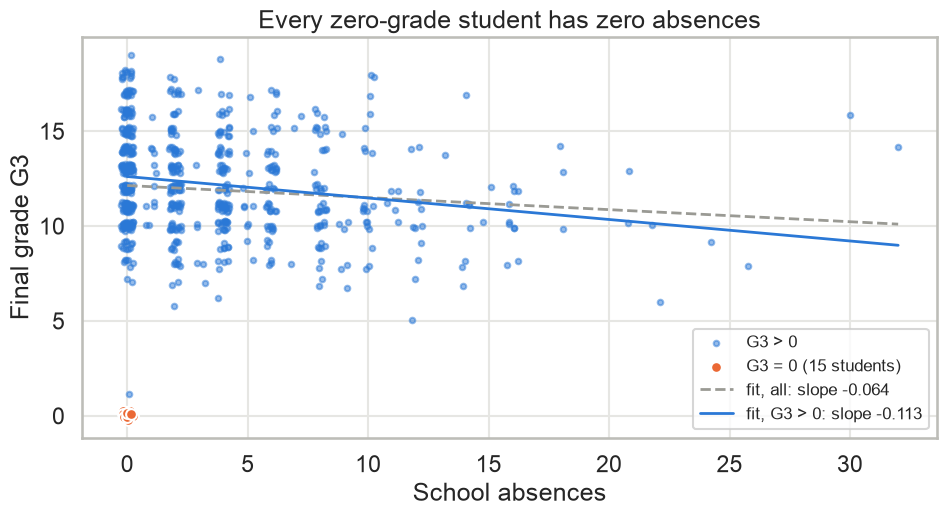

In [7]:
print("absences:", df.absences.describe().round(2).to_dict())
for label, d in [("all", df), ("G3 > 0", nz)]:
    r, p = stats.pearsonr(d.absences, d.G3)
    print(f"{label:7s} n={len(d)}: Pearson r(absences, G3) = {r:+.3f}, p = {p:.2g}")
fig, ax = plt.subplots(figsize=(10, 5.5))
jit = np.random.default_rng(1).uniform(-0.25, 0.25, (2, len(df)))
ax.scatter(nz.absences + jit[0][~df.zero_grade], nz.G3 + jit[1][~df.zero_grade], s=16, alpha=0.5, color=BLUE, label="G3 > 0")
ax.scatter(df.absences[df.zero_grade] + jit[0][df.zero_grade], df.G3[df.zero_grade] + jit[1][df.zero_grade], s=60, color=ORANGE,
           edgecolor="white", lw=1.5, label=f"G3 = 0 ({int(df.zero_grade.sum())} students)")
for d, c, ls, lab in [(df, GREY, "--", "fit, all"), (nz, BLUE, "-", "fit, G3 > 0")]:
    b = np.polyfit(d.absences, d.G3, 1)
    xs = np.array([0, df.absences.max()])
    ax.plot(xs, np.polyval(b, xs), color=c, ls=ls, lw=2, label=f"{lab}: slope {b[0]:+.3f}")
ax.set(xlabel="School absences", ylabel="Final grade G3", title="Every zero-grade student has zero absences")
ax.legend(fontsize=12, loc="lower right")
savefig(fig, "04_absences_vs_g3_zero_grades")

**Interpretation:** With the zero-grade cases included, absences barely relate to G3 (r = -0.091, slope -0.064 per absence); without them the association roughly doubles (r = -0.196, p = 6.5e-7, slope -0.113), because the 15 zeros at 0 absences drag the left end of the line down.

## 6. Who studies more? (confounding check)

          n  share_female  mean_failures  mean_Walc  share_higher  \
study                                                               
<2 h    212          0.42           0.33       2.68          0.79   
2-5 h   305          0.65           0.20       2.18          0.94   
5-10 h   97          0.77           0.10       1.85          0.96   
>10 h    35          0.60           0.06       1.97          0.94   

        mean_absences  
study                  
<2 h             4.34  
2-5 h            3.60  
5-10 h           2.62  
>10 h            2.94  


saved figures/05_who_studies.png


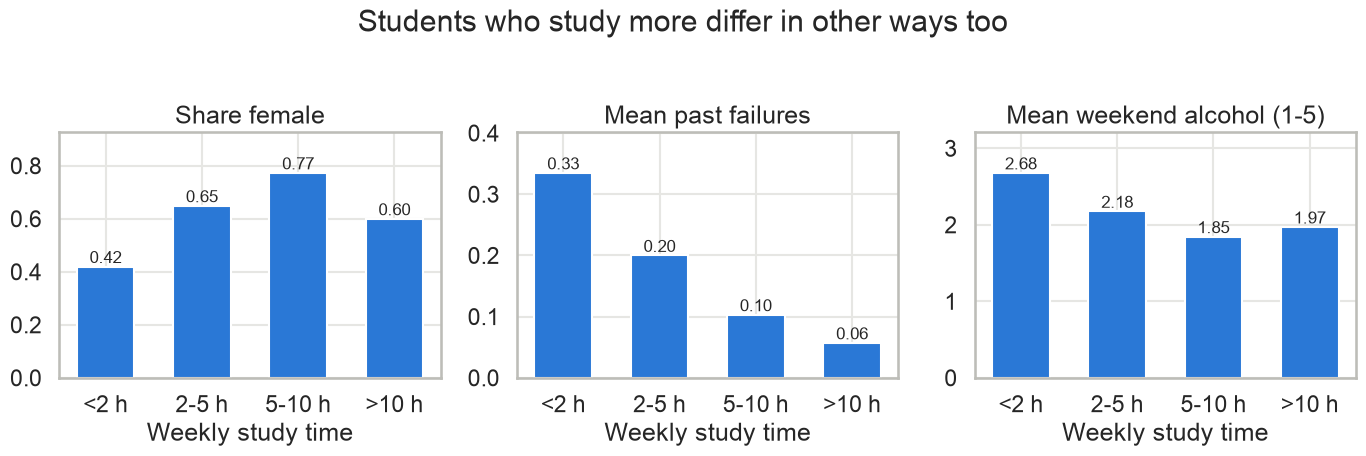

In [8]:
who = df.groupby("study", observed=True).agg(n=("G3", "size"), share_female=("sex", lambda s: (s == "F").mean()),
                                             mean_failures=("failures", "mean"), mean_Walc=("Walc", "mean"),
                                             share_higher=("higher", lambda s: (s == "yes").mean()),
                                             mean_absences=("absences", "mean"))
print(who.round(2))
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for ax, col, title in zip(axes, ["share_female", "mean_failures", "mean_Walc"],
                          ["Share female", "Mean past failures", "Mean weekend alcohol (1-5)"]):
    ax.bar(who.index.astype(str), who[col], color=BLUE, width=0.6)
    for i, v in enumerate(who[col]):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=12)
    ax.set(title=title, xlabel="Weekly study time", ylim=(0, who[col].max() * 1.2))
fig.suptitle("Students who study more differ in other ways too", y=1.03)
savefig(fig, "05_who_studies")

**Interpretation:** Students who study more are more often female (42% to 77% from <2 h to 5-10 h), have fewer past failures (0.33 to 0.06) and drink less at weekends (2.68 to 1.85-1.97), so part of the raw study-time gap is likely confounding.

       count        mean       
sex        F    M      F      M
study                          
<2 h      89  123  11.19  10.59
2-5 h    198  107  12.20  11.90
5-10 h    75   22  13.12  13.59
>10 h     21   14  14.19  11.36
Welch t-test G3 girls vs boys: 12.25 vs 11.41, t = 3.27, p = 0.0011
saved figures/06_g3_by_studytime_and_sex.png


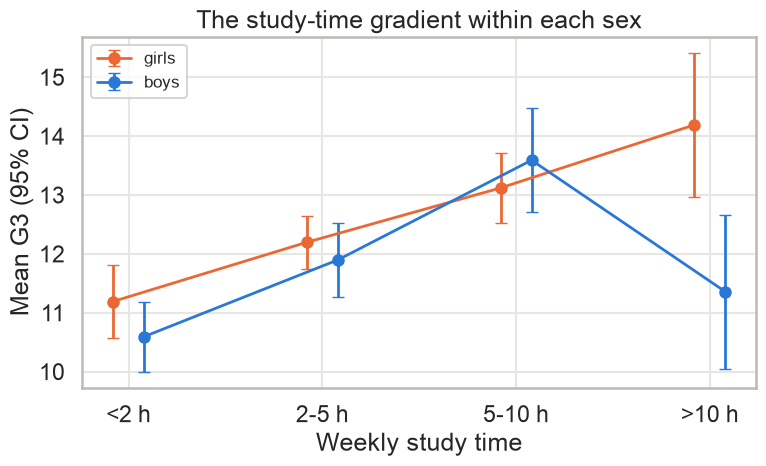

In [9]:
sex_tab = df.groupby(["sex", "study"], observed=True).G3.agg(["count", "mean"]).round(2).unstack(0)
print(sex_tab)
f, m = df[df.sex == "F"].G3, df[df.sex == "M"].G3
t = stats.ttest_ind(f, m, equal_var=False)
print(f"Welch t-test G3 girls vs boys: {f.mean():.2f} vs {m.mean():.2f}, t = {t.statistic:.2f}, p = {t.pvalue:.4f}")
fig, ax = plt.subplots(figsize=(8, 5))
for s, c, off in [("F", ORANGE, -0.08), ("M", BLUE, 0.08)]:
    g = df[df.sex == s].groupby("study", observed=True).G3.agg(["mean", "sem"])
    ax.errorbar(np.arange(4) + off, g["mean"], yerr=1.96 * g["sem"], fmt="o-", color=c, ms=8, lw=2, capsize=4,
                label="girls" if s == "F" else "boys")
ax.set_xticks(range(4), list(ST_LABELS.values()))
ax.set(xlabel="Weekly study time", ylabel="Mean G3 (95% CI)", title="The study-time gradient within each sex")
ax.legend(fontsize=12)
savefig(fig, "06_g3_by_studytime_and_sex")

**Interpretation:** Girls outscore boys overall (12.25 vs 11.41, Welch t = 3.27, p = 0.001), and the gradient holds within each sex up to 5-10 h; the only break is boys at >10 h (11.36, n = 14), which is too small a group to read much into.

## 7. Maths file (context only)

In [10]:
print(mat.groupby("studytime").G3.agg(["count", "mean"]).round(2))

           count   mean
studytime              
1            105  10.05
2            198  10.17
3             65  11.40
4             27  11.26


**Interpretation:** The maths file shows a weaker version of the same gradient (10.05, 10.17, 11.40, 11.26), with the same plateau at the top.

## 8. Pilot check
Automatic comparison of the numbers above with readme section 5.

In [11]:
z = df[df.zero_grade]
anova = stats.f_oneway(*[g.G3 for _, g in df.groupby("studytime")])
checks = {
    "mean G3 <2h (10.84)": (df[df.studytime == 1].G3.mean(), 10.84),
    "mean G3 2-5h (12.09)": (df[df.studytime == 2].G3.mean(), 12.09),
    "mean G3 5-10h (13.23)": (df[df.studytime == 3].G3.mean(), 13.23),
    "mean G3 >10h (13.06)": (df[df.studytime == 4].G3.mean(), 13.06),
    "n >10h (35)": ((df.studytime == 4).sum(), 35),
    "ANOVA F (15.88)": (anova.statistic, 15.88),
    "zero-grade cases (15)": (len(z), 15),
    "zero-grade cases with 0 absences (15)": ((z.absences == 0).sum(), 15),
    "zero-grade mean G1 (7.1)": (z.G1.mean(), 7.1),
    "zero-grade mean G2 (3.8)": (z.G2.mean(), 3.8),
    "zero-grade cases at MS (14)": ((z.school == "MS").sum(), 14),
    "share absences==0 (0.376)": ((df.absences == 0).mean(), 0.376),
    "corr G1,G3 (0.83)": (df.G1.corr(df.G3), 0.83),
    "corr G2,G3 (0.92)": (df.G2.corr(df.G3), 0.92),
    "r(abs,G3) all (-0.09)": (df.absences.corr(df.G3), -0.09),
    "r(abs,G3) G3>0 (-0.20)": (nz.absences.corr(nz.G3), -0.20),
    "share female 5-10h (0.77)": ((df[df.studytime == 3].sex == "F").mean(), 0.77),
    "maths zero-grade cases (38)": (int(mat.zero_grade.sum()), 38),
}
res = pd.DataFrame([{"check": k, "notebook": round(float(v), 3), "pilot": p,
                     "match": abs(float(v) - p) <= 0.006 + 0.005 * abs(p)} for k, (v, p) in checks.items()])
print("all match:", res.match.all())
res

all match: True


,check,notebook,pilot,match
0,mean G3 <2h (10.84),10.844,10.840,True
1,mean G3 2-5h (12.09),12.092,12.090,True
2,mean G3 5-10h (13.23),13.227,13.230,True
3,mean G3 >10h (13.06),13.057,13.060,True
4,n >10h (35),35.000,35.000,True
5,ANOVA F (15.88),15.876,15.880,True
6,zero-grade cases (15),15.000,15.000,True
7,zero-grade cases with 0 absences (15),15.000,15.000,True
8,zero-grade mean G1 (7.1),7.067,7.100,True
9,zero-grade mean G2 (3.8),3.800,3.800,True
